<a href="https://colab.research.google.com/github/rfroiman/DI_Bootcamp/blob/main/Week8/Day3/Text_Analysis_Books_WordCloud_Daily_Challenge.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip -q install nltk spacy wordcloud scikit-learn matplotlib requests
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 88.5 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [9]:
import requests
import re

urls = [
    "https://raw.githubusercontent.com/GITenberg/Alice-s-Adventures-in-Wonderland_11/master/11-0.txt",
    "https://raw.githubusercontent.com/GITenberg/Through-the-Looking-Glass_12/master/12-0.txt",
    "https://raw.githubusercontent.com/GITenberg/A-Tangled-Tale_29042/master/29042.txt"
]

book_titles = [
    "Alice's Adventures in Wonderland",
    "Through the Looking-Glass",
    "A Tangled Tale"
]

def load_texts(urls):
    corpus = []

    for url in urls:
        response = requests.get(url, timeout=30)
        response.raise_for_status()
        text = response.text

        # Remove Project Gutenberg headers and footers
        start = re.search(r"\*\*\*\s*START OF (?:THE|THIS) PROJECT GUTENBERG EBOOK.*?\*\*\*", text, re.IGNORECASE)
        end = re.search(r"\*\*\*\s*END OF (?:THE|THIS) PROJECT GUTENBERG EBOOK.*?\*\*\*", text, re.IGNORECASE)

        if start:
            text = text[start.end():]
        if end:
            text = text[:re.search(r"\*\*\*\s*END OF (?:THE|THIS) PROJECT GUTENBERG EBOOK.*?\*\*\*", text, re.IGNORECASE).start()]

        # Remove non-word characters and normalize spaces
        text = re.sub(r"[^\w\s]", " ", text)
        text = re.sub(r"\s+", " ", text).strip()

        corpus.append(text)

    return corpus

corpus = load_texts(urls)

for title, text in zip(book_titles, corpus):
    print(f"\n{title}")
    print(text[:200])


Alice's Adventures in Wonderland
ALICE S ADVENTURES IN WONDERLAND Lewis Carroll THE MILLENNIUM FULCRUM EDITION 3 0 CHAPTER I Down the Rabbit Hole Alice was beginning to get very tired of sitting by her sister on the bank and of havin

Through the Looking-Glass
THROUGH THE LOOKING GLASS By Lewis Carroll The Millennium Fulcrum Edition 1 7 CHAPTER I Looking Glass house One thing was certain that the WHITE kitten had had nothing to do with it it was the black k

A Tangled Tale
Produced by Chris Curnow Carla Foust Lindy Walsh and the Online Distributed Proofreading Team at http www pgdp net Music transcribed by Linda Cantoni Transcriber s note Minor punctuation errors have b


In [10]:
# Remove introductory credits from A Tangled Tale
start_position = corpus[2].lower().find("a tangled tale")

if start_position != -1:
    corpus[2] = corpus[2][start_position:]

# Check the beginning of each book
for title, text in zip(book_titles, corpus):
    print(f"\n{title}")
    print(text[:200])


Alice's Adventures in Wonderland
ALICE S ADVENTURES IN WONDERLAND Lewis Carroll THE MILLENNIUM FULCRUM EDITION 3 0 CHAPTER I Down the Rabbit Hole Alice was beginning to get very tired of sitting by her sister on the bank and of havin

Through the Looking-Glass
THROUGH THE LOOKING GLASS By Lewis Carroll The Millennium Fulcrum Edition 1 7 CHAPTER I Looking Glass house One thing was certain that the WHITE kitten had had nothing to do with it it was the black k

A Tangled Tale
A TANGLED TALE Decoration Illustration AT A PACE OF SIX MILES IN THE HOUR _Frontispiece _ A TANGLED TALE BY LEWIS CARROLL _WITH SIX ILLUSTRATIONS_ BY ARTHUR B FROST Hoc meum tale quale est accipe _SEC


In [8]:
import requests

api_url = "https://api.github.com/repos/GITenberg/A-Tangled-Tale_29042/contents"

response = requests.get(api_url, timeout=30)
print("Status:", response.status_code)

if response.ok:
    for file in response.json():
        print(file["name"])

Status: 200
29042-8.txt
29042-h
29042.txt
CONTRIBUTING.rst
LICENSE
README.rst
metadata.yaml
pg29042.rdf


In [11]:
import nltk
from nltk.tokenize import wordpunct_tokenize

tokenized_books = [
    wordpunct_tokenize(text.lower())
    for text in corpus
]

for title, tokens in zip(book_titles, tokenized_books):
    print(f"\n{title}")
    print("Total tokens:", len(tokens))
    print("First 150 tokens:", tokens[:150])


Alice's Adventures in Wonderland
Total tokens: 27356
First 150 tokens: ['alice', 's', 'adventures', 'in', 'wonderland', 'lewis', 'carroll', 'the', 'millennium', 'fulcrum', 'edition', '3', '0', 'chapter', 'i', 'down', 'the', 'rabbit', 'hole', 'alice', 'was', 'beginning', 'to', 'get', 'very', 'tired', 'of', 'sitting', 'by', 'her', 'sister', 'on', 'the', 'bank', 'and', 'of', 'having', 'nothing', 'to', 'do', 'once', 'or', 'twice', 'she', 'had', 'peeped', 'into', 'the', 'book', 'her', 'sister', 'was', 'reading', 'but', 'it', 'had', 'no', 'pictures', 'or', 'conversations', 'in', 'it', 'and', 'what', 'is', 'the', 'use', 'of', 'a', 'book', 'thought', 'alice', 'without', 'pictures', 'or', 'conversations', 'so', 'she', 'was', 'considering', 'in', 'her', 'own', 'mind', 'as', 'well', 'as', 'she', 'could', 'for', 'the', 'hot', 'day', 'made', 'her', 'feel', 'very', 'sleepy', 'and', 'stupid', 'whether', 'the', 'pleasure', 'of', 'making', 'a', 'daisy', 'chain', 'would', 'be', 'worth', 'the', 'trouble

In [12]:
import nltk
from nltk.corpus import stopwords

nltk.download("stopwords")

stop_words = set(stopwords.words("english"))

filtered_books = [
    [word for word in tokens if word not in stop_words and word.isalpha()]
    for tokens in tokenized_books
]

words_to_check = [
    "i", "me", "my", "myself",
    "we", "our", "ours", "ourselves"
]

for title, tokens in zip(book_titles, filtered_books):
    print(f"\n{title}")
    print("Remaining tokens:", len(tokens))

    for word in words_to_check:
        print(f"{word}: {tokens.count(word)}")


Alice's Adventures in Wonderland
Remaining tokens: 12252
i: 0
me: 0
my: 0
myself: 0
we: 0
our: 0
ours: 0
ourselves: 0

Through the Looking-Glass
Remaining tokens: 13774
i: 0
me: 0
my: 0
myself: 0
we: 0
our: 0
ours: 0
ourselves: 0

A Tangled Tale
Remaining tokens: 13550
i: 0
me: 0
my: 0
myself: 0
we: 0
our: 0
ours: 0
ourselves: 0


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [13]:
from nltk.stem import PorterStemmer

stemmer = PorterStemmer()

stemmed_books = [
    [stemmer.stem(word) for word in tokens]
    for tokens in filtered_books
]

for title, tokens in zip(book_titles, stemmed_books):
    print(f"\n{title}")
    print("First 50 stemmed tokens:")
    print(tokens[:50])


Alice's Adventures in Wonderland
First 50 stemmed tokens:
['alic', 'adventur', 'wonderland', 'lewi', 'carrol', 'millennium', 'fulcrum', 'edit', 'chapter', 'rabbit', 'hole', 'alic', 'begin', 'get', 'tire', 'sit', 'sister', 'bank', 'noth', 'twice', 'peep', 'book', 'sister', 'read', 'pictur', 'convers', 'use', 'book', 'thought', 'alic', 'without', 'pictur', 'convers', 'consid', 'mind', 'well', 'could', 'hot', 'day', 'made', 'feel', 'sleepi', 'stupid', 'whether', 'pleasur', 'make', 'daisi', 'chain', 'would', 'worth']

Through the Looking-Glass
First 50 stemmed tokens:
['look', 'glass', 'lewi', 'carrol', 'millennium', 'fulcrum', 'edit', 'chapter', 'look', 'glass', 'hous', 'one', 'thing', 'certain', 'white', 'kitten', 'noth', 'black', 'kitten', 'fault', 'entir', 'white', 'kitten', 'face', 'wash', 'old', 'cat', 'last', 'quarter', 'hour', 'bear', 'pretti', 'well', 'consid', 'see', 'hand', 'mischief', 'way', 'dinah', 'wash', 'children', 'face', 'first', 'held', 'poor', 'thing', 'ear', 'one', '

In [14]:
import spacy

nlp = spacy.load("en_core_web_sm")

lemmatized_books = []

for title, tokens in zip(book_titles, filtered_books):
    doc = nlp(" ".join(tokens))
    lemmas = [token.lemma_.lower() for token in doc if token.is_alpha]

    lemmatized_books.append(lemmas)

    print(f"\n{title}")
    print("First 50 lemmatized tokens:")
    print(lemmas[:50])


Alice's Adventures in Wonderland
First 50 lemmatized tokens:
['alice', 'adventures', 'wonderland', 'lewis', 'carroll', 'millennium', 'fulcrum', 'edition', 'chapter', 'rabbit', 'hole', 'alice', 'begin', 'get', 'tired', 'sit', 'sister', 'bank', 'nothing', 'twice', 'peep', 'book', 'sister', 'read', 'picture', 'conversation', 'use', 'book', 'think', 'alice', 'without', 'picture', 'conversation', 'consider', 'mind', 'well', 'could', 'hot', 'day', 'make', 'feel', 'sleepy', 'stupid', 'whether', 'pleasure', 'make', 'daisy', 'chain', 'would', 'worth']

Through the Looking-Glass
First 50 lemmatized tokens:
['look', 'glass', 'lewis', 'carroll', 'millennium', 'fulcrum', 'edition', 'chapter', 'look', 'glass', 'house', 'one', 'thing', 'certain', 'white', 'kitten', 'nothing', 'black', 'kitten', 'fault', 'entirely', 'white', 'kitten', 'face', 'wash', 'old', 'cat', 'last', 'quarter', 'hour', 'bear', 'pretty', 'well', 'consider', 'see', 'hand', 'mischief', 'way', 'dinah', 'wash', 'child', 'face', 'firs

### Stemming vs. Lemmatization Analysis

Stemming reduces words by removing suffixes, sometimes producing incomplete or non-dictionary forms, such as "adventur", "lewi", and "sleepi".

Lemmatization uses linguistic information to identify the base form of words, producing more meaningful results such as "adventures", "lewis", "sleepy", and "child".

Lemmatization is generally more suitable for text interpretation because it preserves word meaning better than stemming.

In [15]:
import nltk

nltk.download("averaged_perceptron_tagger_eng")

pos_tagged_books = []

for title, tokens in zip(book_titles, tokenized_books):
    tags = nltk.pos_tag(tokens)
    pos_tagged_books.append(tags)

    print(f"\n{title}")
    print("Total tagged tokens:", len(tags))
    print("First 50 POS tags:")
    print(tags[:50])

[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.



Alice's Adventures in Wonderland
Total tagged tokens: 27356
First 50 POS tags:
[('alice', 'NN'), ('s', 'NN'), ('adventures', 'NNS'), ('in', 'IN'), ('wonderland', 'NN'), ('lewis', 'NN'), ('carroll', 'VBP'), ('the', 'DT'), ('millennium', 'NN'), ('fulcrum', 'NN'), ('edition', 'NN'), ('3', 'CD'), ('0', 'CD'), ('chapter', 'NN'), ('i', 'VBP'), ('down', 'RP'), ('the', 'DT'), ('rabbit', 'NN'), ('hole', 'JJ'), ('alice', 'NN'), ('was', 'VBD'), ('beginning', 'VBG'), ('to', 'TO'), ('get', 'VB'), ('very', 'RB'), ('tired', 'JJ'), ('of', 'IN'), ('sitting', 'VBG'), ('by', 'IN'), ('her', 'PRP$'), ('sister', 'NN'), ('on', 'IN'), ('the', 'DT'), ('bank', 'NN'), ('and', 'CC'), ('of', 'IN'), ('having', 'VBG'), ('nothing', 'NN'), ('to', 'TO'), ('do', 'VB'), ('once', 'RB'), ('or', 'CC'), ('twice', 'VB'), ('she', 'PRP'), ('had', 'VBD'), ('peeped', 'VBN'), ('into', 'IN'), ('the', 'DT'), ('book', 'NN'), ('her', 'PRP$')]

Through the Looking-Glass
Total tagged tokens: 30646
First 50 POS tags:
[('through', 'IN'),

In [17]:
import nltk

nltk.download("maxent_ne_chunker_tab")
nltk.download("words")

named_entities_books = []

for title, text in zip(book_titles, corpus):
    # Preserve original capitalization where available
    tokens = nltk.wordpunct_tokenize(text)
    tagged_tokens = nltk.pos_tag(tokens)
    entity_tree = nltk.ne_chunk(tagged_tokens)

    entities = [
        (" ".join(word for word, tag in subtree.leaves()), subtree.label())
        for subtree in entity_tree
        if isinstance(subtree, nltk.Tree)
    ]

    named_entities_books.append(entities)

    print(f"\n{title}")
    print("First 30 named entities:")
    print(entities[:30])

[nltk_data] Downloading package maxent_ne_chunker_tab to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package maxent_ne_chunker_tab is already up-to-date!
[nltk_data] Downloading package words to /root/nltk_data...
[nltk_data]   Package words is already up-to-date!



Alice's Adventures in Wonderland
First 30 named entities:
[('Lewis Carroll THE', 'PERSON'), ('MILLENNIUM', 'ORGANIZATION'), ('Rabbit Hole', 'ORGANIZATION'), ('White Rabbit', 'FACILITY'), ('Rabbit', 'ORGANIZATION'), ('Rabbit', 'ORGANIZATION'), ('WATCH', 'ORGANIZATION'), ('Alice', 'PERSON'), ('ORANGE', 'ORGANIZATION'), ('Well', 'PERSON'), ('Which', 'PERSON'), ('Alice', 'PERSON'), ('Latitude', 'PERSON'), ('Alice', 'PERSON'), ('Latitude', 'PERSON'), ('Longitude', 'ORGANIZATION'), ('How', 'PERSON'), ('Please Ma', 'PERSON'), ('Australia', 'GPE'), ('Down', 'PERSON'), ('Dinah', 'PERSON'), ('Dinah', 'PERSON'), ('Dinah', 'PERSON'), ('Dinah', 'PERSON'), ('Alice', 'PERSON'), ('White Rabbit', 'FACILITY'), ('Rabbit', 'PERSON'), ('Alice', 'PERSON'), ('Alice', 'PERSON'), ('Alice', 'PERSON')]

Through the Looking-Glass
First 30 named entities:
[('THE', 'ORGANIZATION'), ('LOOKING', 'ORGANIZATION'), ('Lewis Carroll', 'PERSON'), ('Millennium Fulcrum', 'FACILITY'), ('Glass', 'ORGANIZATION'), ('WHITE', 'OR

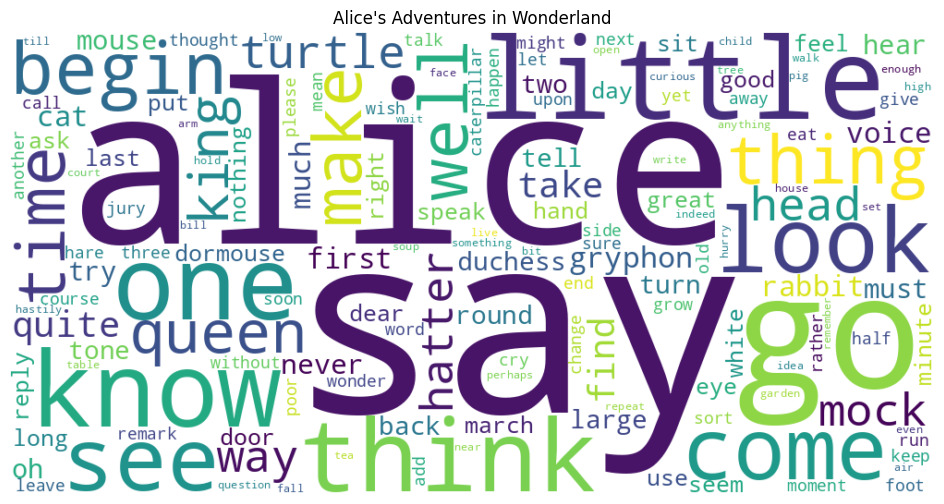

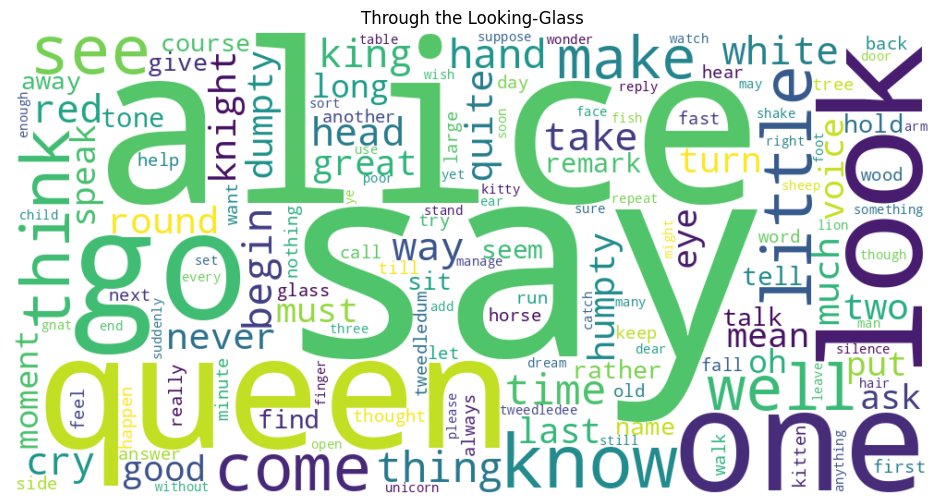

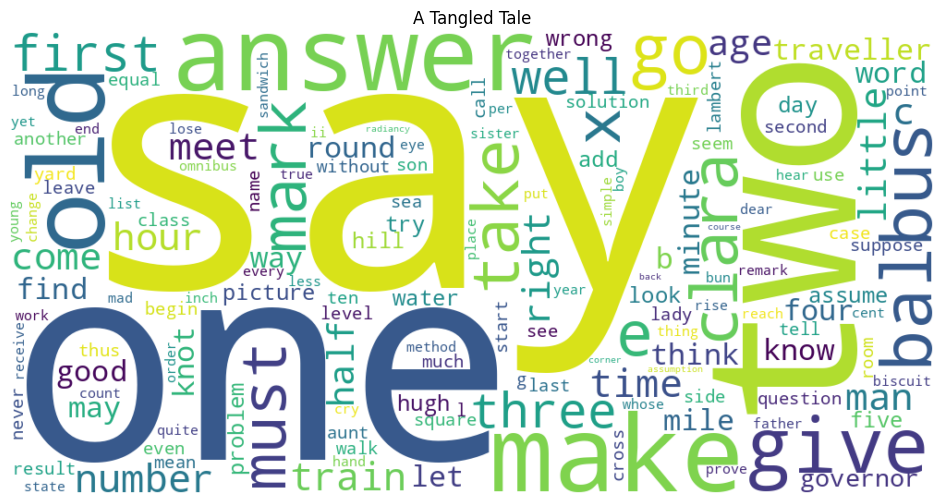

In [18]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

for title, tokens in zip(book_titles, lemmatized_books):
    text = " ".join(tokens)

    wordcloud = WordCloud(
        width=1000,
        height=500,
        background_color="white",
        max_words=150,
        collocations=False
    ).generate(text)

    plt.figure(figsize=(12, 6))
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title(title)
    plt.show()

In [19]:
from sklearn.feature_extraction.text import CountVectorizer
import numpy as np

# Use lemmatized text for Bag of Words
processed_texts = [" ".join(tokens) for tokens in lemmatized_books]

vectorizer = CountVectorizer()
bow_matrix = vectorizer.fit_transform(processed_texts)

words = vectorizer.get_feature_names_out()

for index, title in enumerate(book_titles):
    frequencies = bow_matrix[index].toarray().flatten()
    top_indices = np.argsort(frequencies)[::-1][:5]

    print(f"\n{title}")
    for word_index in top_indices:
        print(f"{words[word_index]}: {frequencies[word_index]}")


Alice's Adventures in Wonderland
say: 530
alice: 399
go: 172
little: 128
know: 107

Through the Looking-Glass
say: 544
alice: 455
queen: 197
go: 179
one: 155

A Tangled Tale
say: 233
one: 204
two: 102
make: 95
old: 92


In [20]:
# Display the first 20 non-zero entries of the BoW matrix
print("BoW Matrix Shape:", bow_matrix.shape)

rows, columns = bow_matrix.nonzero()

print("\nDocument | Word Index | Word | Frequency")

for doc_index, word_index in list(zip(rows, columns))[:20]:
    print(
        f"{doc_index} | "
        f"{word_index} | "
        f"{words[word_index]} | "
        f"{bow_matrix[doc_index, word_index]}"
    )

BoW Matrix Shape: (3, 4628)

Document | Word Index | Word | Frequency
0 | 117 | alice | 399
0 | 70 | adventures | 2
0 | 4557 | wonderland | 4
0 | 2336 | lewis | 2
0 | 590 | carroll | 2
0 | 2557 | millennium | 1
0 | 1661 | fulcrum | 1
0 | 1273 | edition | 3
0 | 631 | chapter | 12
0 | 3208 | rabbit | 52
0 | 1950 | hole | 5
0 | 361 | begin | 90
0 | 1717 | get | 106
0 | 4104 | tired | 7
0 | 3659 | sit | 34
0 | 3658 | sister | 11
0 | 316 | bank | 4
0 | 2749 | nothing | 34
0 | 4229 | twice | 5
0 | 2917 | peep | 2


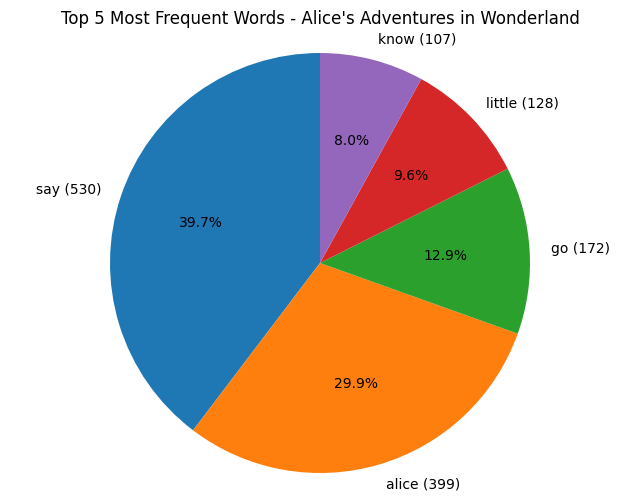

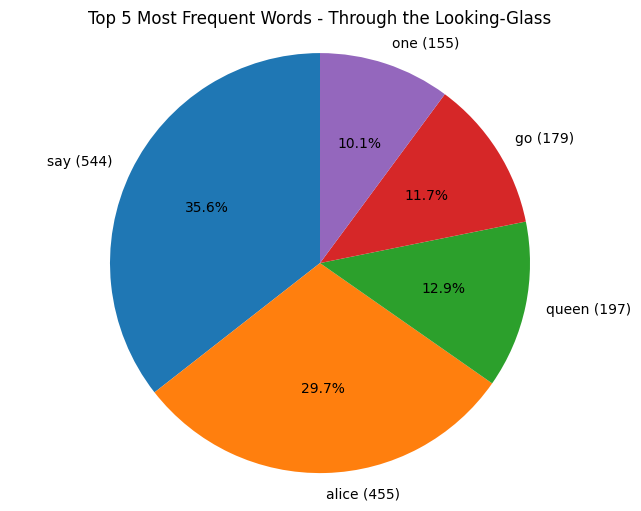

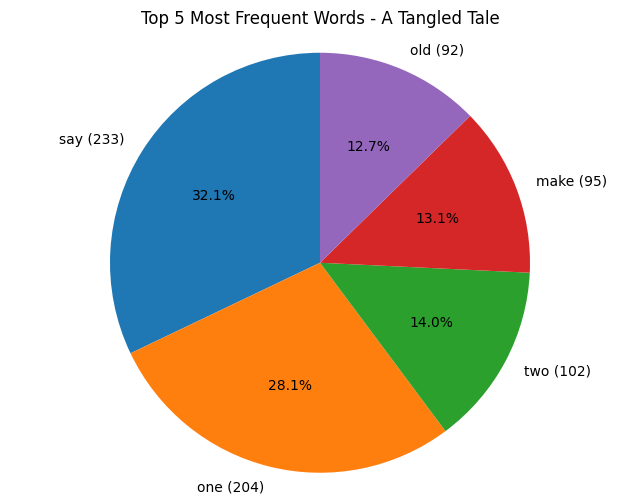

In [21]:
for index, title in enumerate(book_titles):
    frequencies = bow_matrix[index].toarray().flatten()
    top_indices = np.argsort(frequencies)[::-1][:5]

    top_words = words[top_indices]
    top_counts = frequencies[top_indices]

    labels = [
        f"{word} ({count})"
        for word, count in zip(top_words, top_counts)
    ]

    plt.figure(figsize=(8, 6))
    plt.pie(
        top_counts,
        labels=labels,
        autopct="%1.1f%%",
        startangle=90
    )
    plt.title(f"Top 5 Most Frequent Words - {title}")
    plt.axis("equal")
    plt.show()

### Bag of Words Analysis

The most frequent words across the three books include "say", "alice", "go", and "one".

These results are expected because the books contain many dialogues and recurring characters.

Although "alice" and "queen" provide useful information about the stories, common words such as "say" and "go" are less informative.

Bag of Words considers word frequency but does not account for how distinctive a word is across different documents.

TF-IDF can help identify words that are more relevant to each individual book.

In [22]:
from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np

tfidf_vectorizer = TfidfVectorizer(min_df=1, max_df=2)

tfidf_matrix = tfidf_vectorizer.fit_transform(processed_texts)
tfidf_words = tfidf_vectorizer.get_feature_names_out()

print("TF-IDF Matrix Shape:", tfidf_matrix.shape)

for index, title in enumerate(book_titles):
    scores = tfidf_matrix[index].toarray().flatten()
    top_indices = np.argsort(scores)[::-1][:5]

    print(f"\n{title}")
    for word_index in top_indices:
        print(f"{tfidf_words[word_index]}: {scores[word_index]:.4f}")

TF-IDF Matrix Shape: (3, 3847)

Alice's Adventures in Wonderland
gryphon: 0.3379
rabbit: 0.3195
turtle: 0.2850
hatter: 0.2663
mock: 0.2616

Through the Looking-Glass
humpty: 0.3516
dumpty: 0.3516
knight: 0.2977
tweedledum: 0.2256
tweedledee: 0.1725

A Tangled Tale
balbus: 0.3212
clara: 0.2845
train: 0.1850
governor: 0.1514
hugh: 0.1469


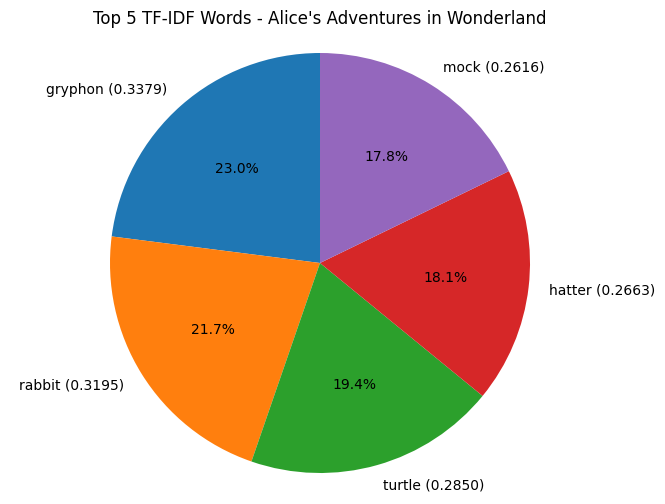

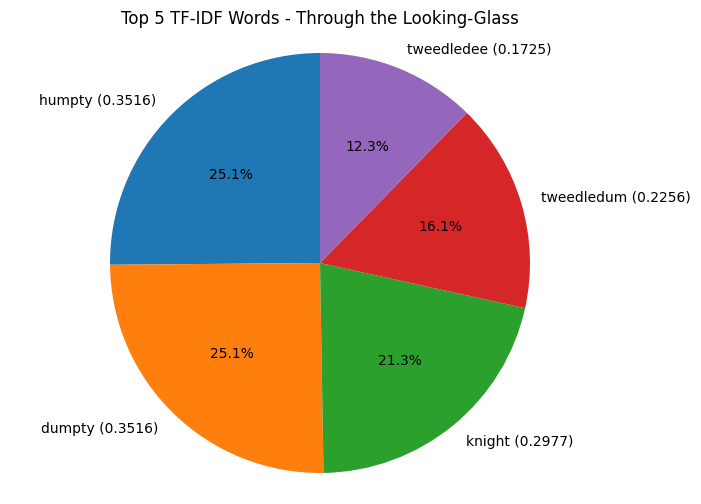

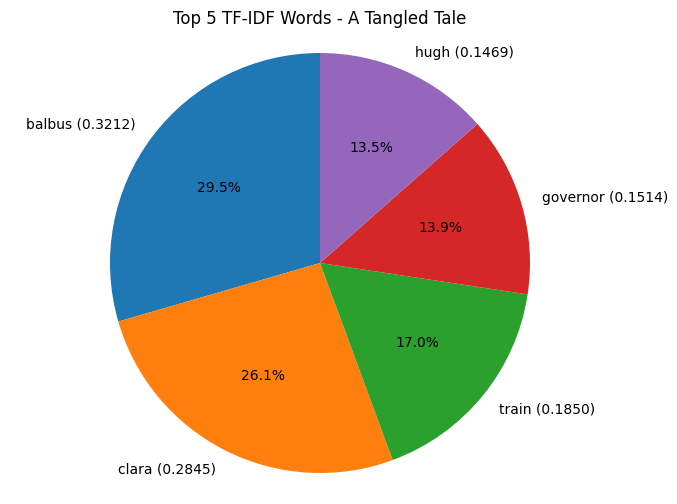

In [23]:
for index, title in enumerate(book_titles):
    scores = tfidf_matrix[index].toarray().flatten()
    top_indices = np.argsort(scores)[::-1][:5]

    top_words = tfidf_words[top_indices]
    top_scores = scores[top_indices]

    labels = [
        f"{word} ({score:.4f})"
        for word, score in zip(top_words, top_scores)
    ]

    plt.figure(figsize=(8, 6))
    plt.pie(
        top_scores,
        labels=labels,
        autopct="%1.1f%%",
        startangle=90
    )
    plt.title(f"Top 5 TF-IDF Words - {title}")
    plt.axis("equal")
    plt.show()

### Final Analysis: Bag of Words vs. TF-IDF

Bag of Words identified frequently occurring words such as "say", "alice", and "go". Although these words are common in the books, they are not always useful for distinguishing one story from another.

TF-IDF produced more distinctive results:

- **Alice's Adventures in Wonderland:** gryphon, rabbit, turtle, hatter, mock.
- **Through the Looking-Glass:** humpty, dumpty, knight, tweedledum, tweedledee.
- **A Tangled Tale:** balbus, clara, train, governor, hugh.

These words provide more meaningful information about the characters and themes of each book.

**Conclusion:** TF-IDF is more effective than simple word frequency for identifying distinctive vocabulary across documents. However, it does not capture the full context or meaning of words.